In [1]:
import sys
import os
import gc
import numpy as np
import matplotlib.pyplot as plt
import h5py, json

In [2]:
#load data
def load_dataset(path):
    with h5py.File(path, "r") as f:
        d = {k: f[k][:] for k in f}
        d["config"] = json.loads(f.attrs["config"])
    return d
name = "only_broadband_5e3"

d = load_dataset(f"data/psd_dataset_{name}.h5")
#in this way, the input is a psd and the output is a label for each state
freq = d["freq"]
X = d["power"]                                  
#above 10^-1.5 rms we define the data as hard state, above 10^-2.5 as intermediate, and below as soft state
start_int = -1.75
end_int = -3.0

print(f"Rms thresholds; max intermediate rms: {np.sqrt(10**start_int)*100:.3f}%, min intermediate rms: {np.sqrt(10**end_int)*100:.3f}%")
y = np.digitize(d["logvar"], [end_int, start_int])   

Rms thresholds; max intermediate rms: 13.335%, min intermediate rms: 3.162%


Coeff shape: (3, 85)
Score: 0.96
Sparsity: 0.00
Balanced accuracy: 0.9594937542970469


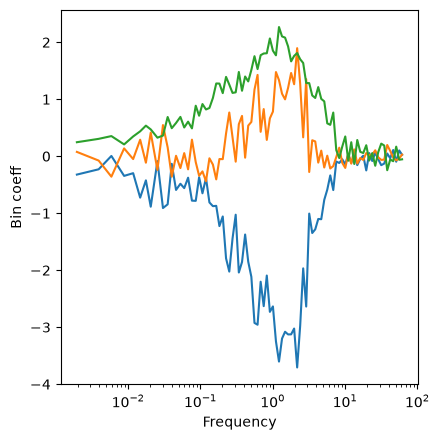

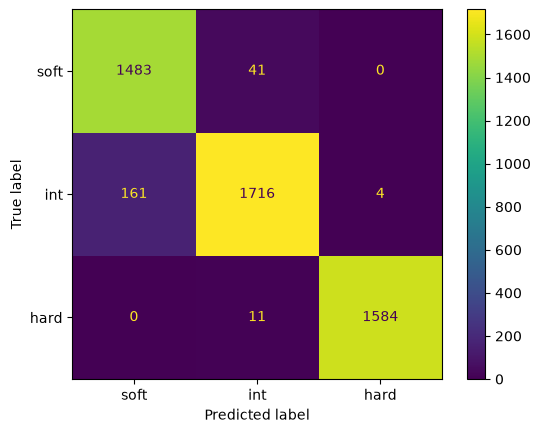

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score

X_scaled = StandardScaler().fit_transform(X)
#just yoloing things
test_LR = LogisticRegression(max_iter=1000)
test_LR.fit(X_scaled,y)
test_coeff = test_LR.coef_
test_sparsity = np.mean(test_coeff == 0) * 100
test_score = test_LR.score(X_scaled,y)

#this just shows that the model separates the full 1000 bins in a single training dataset evently
print(f"Coeff shape: {test_coeff.shape}")
print(f"Score: {test_score:.2f}")
print(f"Sparsity: {test_sparsity:.2f}")

#plot the test coefficients and plot them against frequency 
#to see which bins contribute the most to the variance
fig, ax = plt.subplots(1,1,figsize=(4.5,4.5))
ax.semilogx(freq, test_coeff.T)
ax.set_xlabel("Frequency")
ax.set_ylabel("Bin coeff")
fig.tight_layout()

#also plot the confusion matrix
#obviously we are getting this perfect since it's seen the data in training
ConfusionMatrixDisplay.from_estimator(test_LR, X_scaled, y, display_labels=["soft", "int", "hard"])
print(f"Balanced accuracy: {balanced_accuracy_score(y, test_LR.predict(X_scaled))}")

Test accuracy: 0.946
Accuracy score: 0.9483491986568011


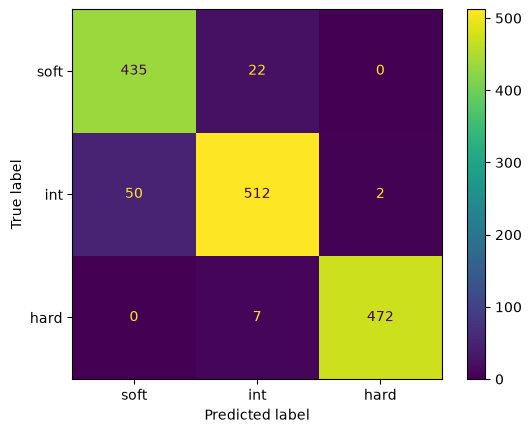

In [4]:
#now turn the above into a non shitty pipeline 
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

#split into training and test data
#stratify keeps the proportions of the different classes identical after splitting
#random_state sets the seed and is useful for when we compare methods with the same
#training/test data
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

#make a pipeline which first scales the data, then fits a logistic regression model to the training data
logistic_pipeline = make_pipeline(StandardScaler(), 
                                  LogisticRegression(max_iter=1000))
logistic_pipeline.fit(X_tr, y_tr)
#now check performance on the test data
print(f"Test accuracy: {logistic_pipeline.score(X_te, y_te)}")

#and the confusion matrix again
#also plot the confusion matrix
ConfusionMatrixDisplay.from_estimator(logistic_pipeline, X_te, y_te, display_labels=["soft", "int", "hard"])
#average recall per class
print(f"Accuracy score: {balanced_accuracy_score(y_te, logistic_pipeline.predict(X_te))}")

rms-only score: 0.886
Rms-only balanced accuracy: 0.8935175434040762


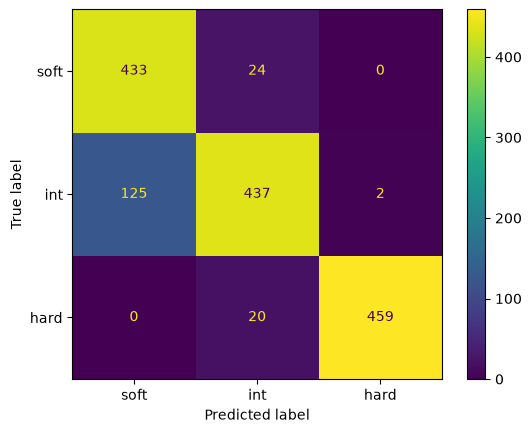

In [5]:
#now we try the same, but using the integrated PSD instead
rms_feat = (X * np.gradient(d["freq"])).sum(axis=1, keepdims=True)

r_tr, r_te = train_test_split(rms_feat, test_size=0.3, stratify=y, random_state=0)
rms_pipeline = make_pipeline(StandardScaler(), LogisticRegression()).fit(r_tr, y_tr)
print(f"rms-only score: {rms_pipeline.score(r_te, y_te)}")

ConfusionMatrixDisplay.from_estimator(rms_pipeline, r_te, y_te, display_labels=["soft", "int", "hard"])
#average recall per class
print(f"Rms-only balanced accuracy: {balanced_accuracy_score(y_te, rms_pipeline.predict(r_te))}")

rms-only score: 0.9266666666666666
Rms-only balanced accuracy: 0.9253978404826673


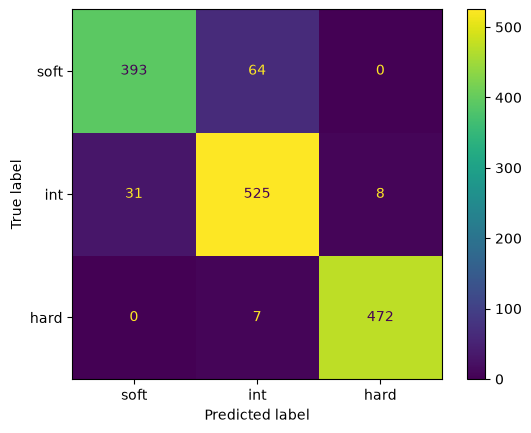

In [6]:
#clipping to protect from Nan, take log10 of the rms to make the data more tractable
rms_feat = np.log10(np.clip((X * np.gradient(d["freq"])).sum(axis=1, keepdims=True), 1e-6, None))

r_tr, r_te = train_test_split(rms_feat, test_size=0.3, stratify=y, random_state=0)
rms_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(r_tr, y_tr)
print(f"rms-only score: {rms_pipeline.score(r_te, y_te)}")

ConfusionMatrixDisplay.from_estimator(rms_pipeline, r_te, y_te, display_labels=["soft", "int", "hard"])
#average recall per class
print(f"Rms-only balanced accuracy: {balanced_accuracy_score(y_te, rms_pipeline.predict(r_te))}")

In [7]:
#let us compare over many training:test splits whether integrating over rms is better or not
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
for name, model, feats in [("full PSD", logistic_pipeline, X), ("rms only", rms_pipeline, rms_feat)]:
    s = cross_val_score(model, feats, y, cv=cv, scoring="balanced_accuracy")
    print(f"{name}: {s.mean():.3f} ± {s.std():.3f}")

#it's not

full PSD: 0.950 ± 0.007
rms only: 0.924 ± 0.007


Renormalisation score: 0.614
Renormalisation balanced accuracy: 0.5916754081379071


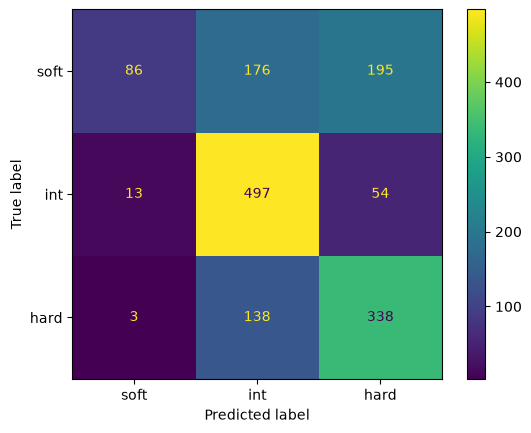

In [8]:
#now let us try to renormalize by the total rms the model started from
#and see if it learns the shape at all
X_norm = X / 10**d["logvar"][:, None]

norm_tr, norm_te = train_test_split(X_norm, test_size=0.3, stratify=y, random_state=0)
norm_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(norm_tr, y_tr)
print(f"Renormalisation score: {norm_pipeline.score(norm_te, y_te)}")

ConfusionMatrixDisplay.from_estimator(norm_pipeline, norm_te, y_te, display_labels=["soft", "int", "hard"])
#average recall per class
print(f"Renormalisation balanced accuracy: {balanced_accuracy_score(y_te, norm_pipeline.predict(norm_te))}")

#so basically the ims, which has a different shape, is reconstructed well
#the soft and hard states are confused because they are both flat-top, and the confusion is made worse
#by the data sometimes having low s:n so the classifier kind of just guesses

Renormalisation score: 0.5953333333333334
Renormalisation balanced accuracy: 0.5689886565148424


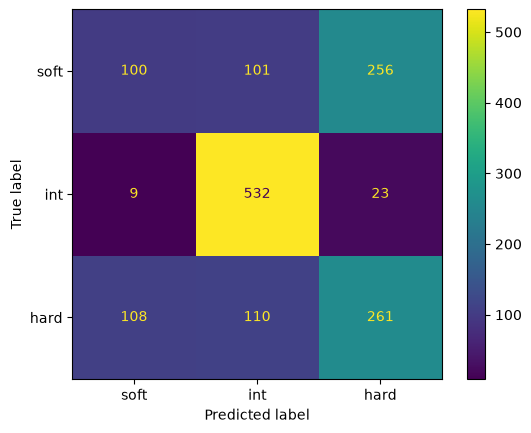

In [9]:
#next: use the noise-free models as data instead
#it doesn't which is not surprising, in the generated data the soft and hard PSDs have exactly the same shape
#just different rms
M = d["model"]      

M_norm = M / 10**d["logvar"][:, None]

mod_tr, mod_te = train_test_split(M_norm, test_size=0.3, stratify=y, random_state=0)
mod_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(mod_tr, y_tr)
print(f"Renormalisation score: {mod_pipeline.score(mod_te, y_te)}")

ConfusionMatrixDisplay.from_estimator(mod_pipeline, mod_te, y_te, display_labels=["soft", "int", "hard"])
#average recall per class
print(f"Renormalisation balanced accuracy: {balanced_accuracy_score(y_te, mod_pipeline.predict(mod_te))}")

In [10]:
#so what we concluded is that the rms separates hard from soft, and the shape separates intermediate from soft/hard
#note: also we have to be careful in how the data is labelled, with splits at -2.5 and -1.5 instead the classifier 
#is told that some intermediate states are actually soft states, so the results are skewed strangely